# Customer Churn Prediction

- **Subject:** Artificial Intelligence, Final Project (Question 1)
- **Batch:** 3
- **Name:** Muhammad Faizan
- **Instructor:** Akbar Ali
- **Organization:** Hunarmand Punjab

Churn means a customer leaves a service. A company loses less money if it can find these customers early and offer them something to stay.

In this project I use data from a telecom company to predict if a customer will churn (Yes or No). This is a **classification** problem because the answer is a category, not a number. I train two models, Logistic Regression and KNN, and compare them.

## 1. Import libraries

In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# all charts and tables are saved in this folder
os.makedirs("outputs", exist_ok=True)

## 2. Load the dataset

I use the IBM Telco Customer Churn dataset. Each row is one customer and the `Churn` column tells us if they left. If the CSV is not in the `data` folder (for example on Google Colab), it is loaded from the internet.

In [2]:
file_path = "data/Telco-Customer-Churn.csv"
if not os.path.exists(file_path):
    file_path = "https://cdn.jsdelivr.net/gh/IBM/telco-customer-churn-on-icp4d@master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Exploratory Data Analysis (EDA)

Before training any model I want to understand the data.

### How many customers churned?

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


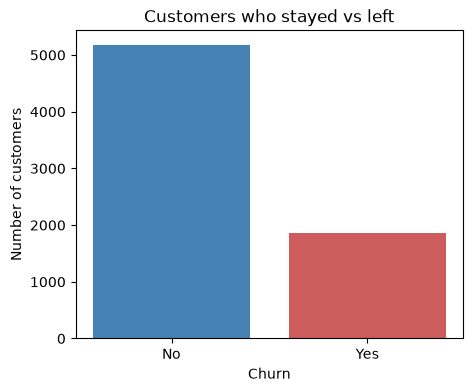

In [4]:
churn_counts = df["Churn"].value_counts()
churn_percent = df["Churn"].value_counts(normalize=True) * 100

print(churn_counts)
print(churn_percent.round(2))

plt.figure(figsize=(5, 4))
plt.bar(churn_counts.index, churn_counts.values, color=["steelblue", "indianred"])
plt.title("Customers who stayed vs left")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.savefig("outputs/churn_count.png", bbox_inches="tight")
plt.show()

Most customers did not churn, so the classes are **imbalanced**. This matters later: a model that always says "No" would still get a high accuracy while finding zero churners. That is why I do not judge the models on accuracy alone.

### Does the contract type matter?

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


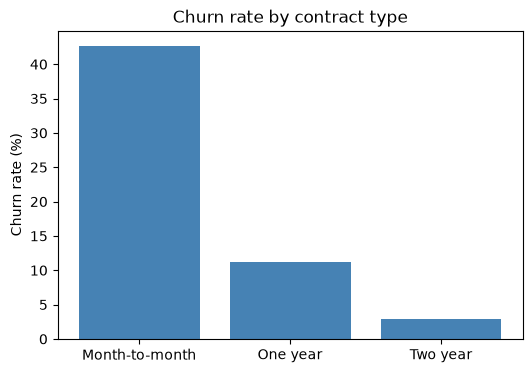

In [5]:
contract_churn = df.groupby("Contract")["Churn"].apply(lambda x: (x == "Yes").mean() * 100)
print(contract_churn.round(1))

plt.figure(figsize=(6, 4))
plt.bar(contract_churn.index, contract_churn.values, color="steelblue")
plt.title("Churn rate by contract type")
plt.ylabel("Churn rate (%)")
plt.savefig("outputs/churn_by_contract.png", bbox_inches="tight")
plt.show()

Contract type makes a very big difference. 42.7% of month-to-month customers left, compared to only 2.8% on a two year contract. A customer on a monthly contract can leave at any time with no penalty.
